# Olist: Barplots y Pie Charts

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")


orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

### 1 Categorías de productos
Utilizando la tabla de productos, determina cuántos productos existen en cada categoría.

Construye una gráfica de barras que muestre las categorías con mayor cantidad de productos.

Pregunta: ¿Qué categorías tienen mayor presencia en el catálogo de Olist?
Requisitos:
Ordena las categorías de mayor a menor.
Agrega un título.
Etiqueta correctamente los ejes.
Utiliza un color para las barras.

<Axes: title={'center': 'Categorias de productos'}, xlabel='Categoría', ylabel='Cantidad de ventas'>

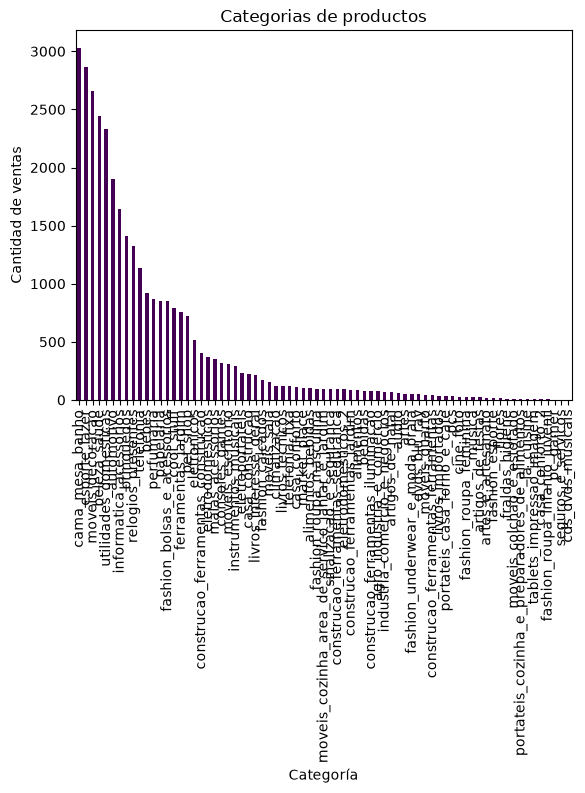

In [2]:
productos = products
productos = products[["product_id", "product_category_name"]]
resultado = productos.groupby("product_category_name")["product_id"].count().sort_values(ascending=False)
resultado.plot(
    kind="bar",
    title="Categorias de productos",
     xlabel="Categoría",
    ylabel="Cantidad de ventas",
    colormap="viridis"
)

### 2 Las 10 categorías principales
La cantidad de categorías de Olist puede hacer que una gráfica sea difícil de leer.

Construye una gráfica de barras mostrando únicamente las 10 categorías con mayor número de productos.

Pregunta: ¿Cuáles son las categorías que tienen mayor presencia en el catálogo?
Requisitos:
* Utiliza barras horizontales si consideras que facilitan la lectura.
* Ordena los resultados.
* Incluye título y etiquetas.

<Axes: title={'center': 'Categorias de productos'}, xlabel='Categoría', ylabel='Cantidad de ventas'>

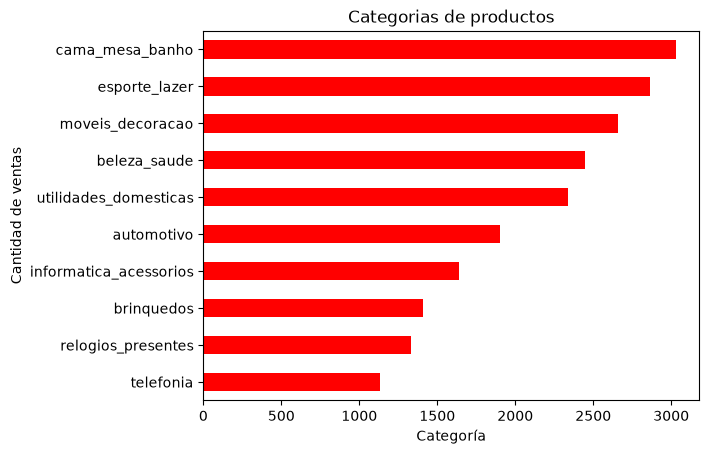

In [3]:
productos = products
productos = products[["product_id", "product_category_name"]]
resultado = productos.groupby("product_category_name")["product_id"].count().nlargest(10)
resultado = resultado.sort_values(ascending=True)
resultado.plot(
    kind="barh",
    title="Categorias de productos",
     xlabel="Categoría",
    ylabel="Cantidad de ventas",
    color="red"
)


### 3 Distribución de productos
Construye un pie chart que muestre cómo se distribuyen los productos entre las categorías.

Para evitar una gráfica ilegible, utiliza solamente las 5 categorías con mayor número de productos y agrupa todas las demás como "Otros".

Pregunta: ¿Qué proporción del catálogo está concentrada en las principales categorías?
Requisitos:
* Mostrar porcentajes.
* Etiquetar las categorías.
* Agregar un título.
* Utilizar colores diferentes.

<Axes: title={'center': 'Distribución de productos'}>

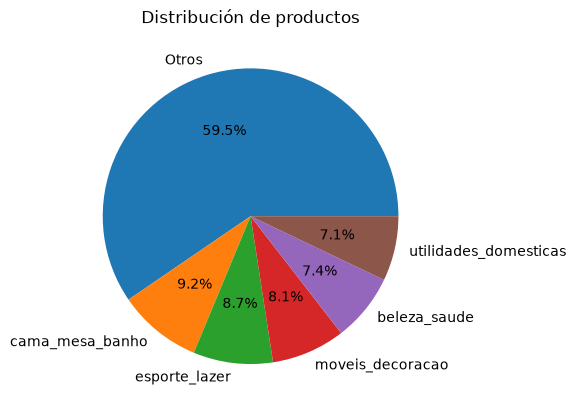

In [4]:
productos = products
productos = productos[["product_category_name", "product_id"]]
top5= productos.groupby("product_category_name")["product_id"].count().nlargest(5)
productos["otros"] = productos['product_category_name'].apply(
    lambda x: x if x in top5 else 'Otros'
)
otros = productos["otros"].value_counts()
otros.plot(
    kind="pie",
    labels=otros.index,
    autopct='%1.1f%%',
    title="Distribución de productos"
)

### 4 Clientes por estado
Utilizando la información de los clientes, determina cuántos clientes existen en cada estado de Brasil.

Construye una gráfica de barras con los estados ordenados de mayor a menor cantidad de clientes.

Pregunta: ¿Qué estados concentran la mayor cantidad de clientes?
Requisitos:
* Mostrar todos los estados.
* Ordenar de mayor a menor.
* Utilizar barras horizontales.
* Agregar título y etiquetas.

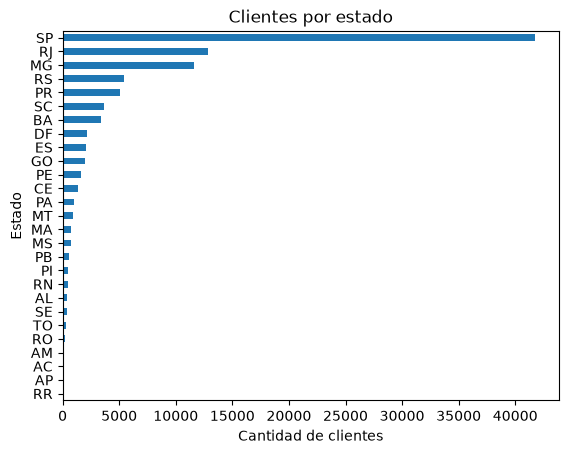

In [5]:
clientes = customers
clientes = clientes["customer_state"].value_counts().sort_values(ascending=True)
ax = clientes.plot(
    kind="barh",
    title="Clientes por estado",
    xlabel="Cantidad de clientes",
    ylabel="Estado"
)

### 5 Estados principales
Construye un pie chart con los 5 estados que concentran mayor cantidad de clientes.

Agrupa todos los demás estados en una categoría llamada "Otros".

Pregunta: ¿Qué tan concentrada está la base de clientes geográficamente?


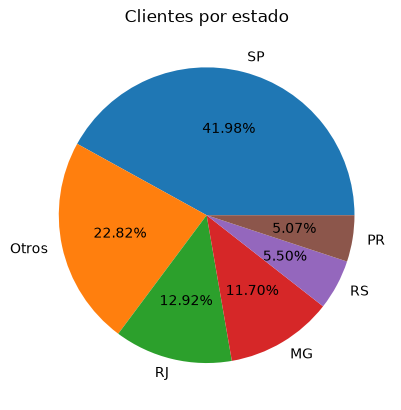

In [6]:
clientes = customers
clientestop = clientes["customer_state"].value_counts().nlargest(5)
clientes["otros"] = clientes['customer_state'].apply(
    lambda x: x if x in clientestop else 'Otros'
)
otros = clientes["otros"].value_counts()
ax = otros.plot(
    kind="pie",
    autopct = "%1.2f%%",
    title="Clientes por estado",
    xlabel="Cantidad de clientes",
)

### 6 Métodos de pago
Utilizando la tabla de pagos, determina cuántos pagos fueron realizados mediante cada método de pago.
Construye primero una gráfica de barras.

* Pregunta: ¿Cuál es el método de pago más utilizado?
Después construye un pie chart utilizando exactamente la misma información.

### Reflexión:
* ¿Cuál de las dos gráficas permite comparar mejor los métodos de pago?

* ¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?

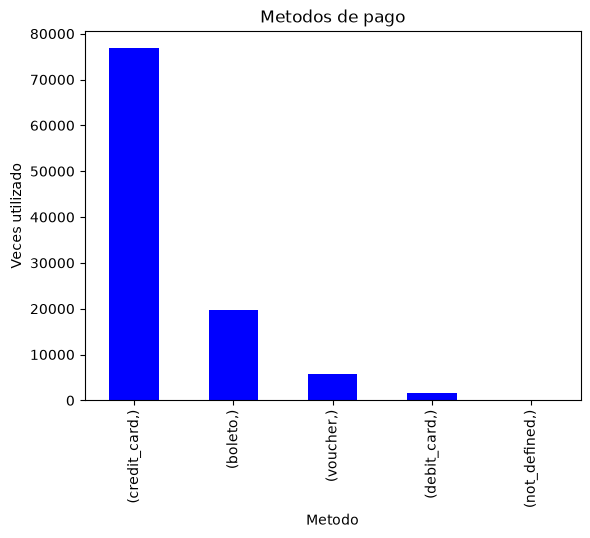

In [7]:
pagos = payments[["payment_type"]]
pagos = pagos.value_counts()
ax = pagos.plot(
    kind="bar",
    title="Metodos de pago",
    xlabel="Metodo",
    ylabel="Veces utilizado",
    color="Blue"
)

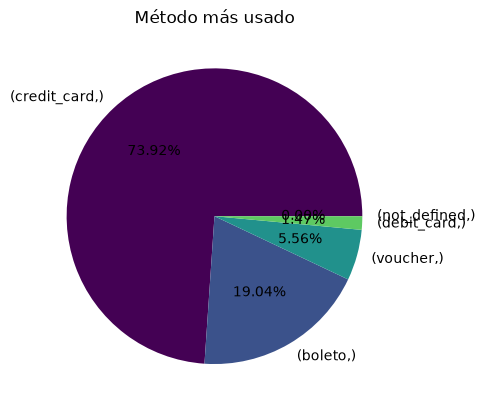

In [8]:
ax=pagos.plot(
    kind="pie",
    autopct = "%1.2f%%",
    title="Método más usado",
    colormap="viridis"
)

De entre las dos gráficas, la que mejor compara los métodos de pagos es la de barras por su facilidad al mometo de mostrar las categorias, sin embargo, si me pidieran representar los datos a proporción, la gráfica más indicada sería la de pastel o "pie"

### 7 Número de cuotas
Utilizando la información de pagos, analiza la cantidad de cuotas registrada en payment_installments.
Agrupa las compras por número de cuotas y construye una gráfica de barras.

* Pregunta: ¿Qué número de cuotas es el más frecuente?
* Reto: Muestra únicamente los valores correspondientes a 1 a 10 cuotas.

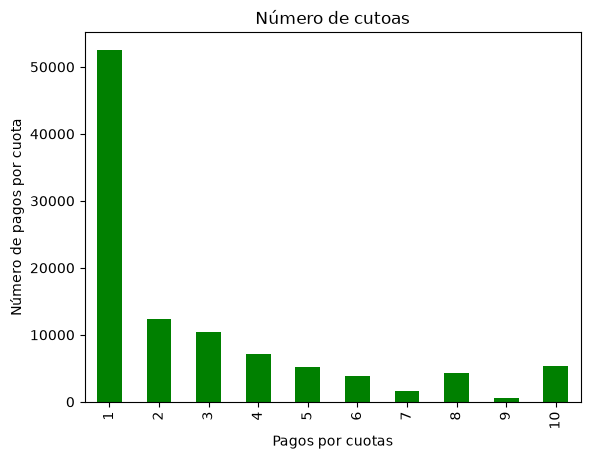

In [9]:
pagos = payments["payment_installments"].value_counts().sort_index().iloc[1:11]
ax = pagos.plot(
    kind="bar",
    color="Green",
    title ="Número de cutoas",
    xlabel="Pagos por cuotas",
    ylabel="Número de pagos por cuota"
)

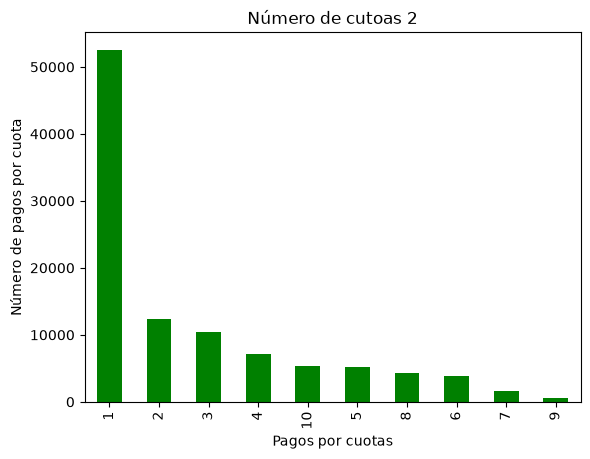

In [10]:
#Ordenado
pagos2 = payments["payment_installments"].value_counts().sort_values().nlargest(10)
ax = pagos2.plot(
    kind="bar",
    color="Green",
    title ="Número de cutoas 2",
    xlabel="Pagos por cuotas",
    ylabel="Número de pagos por cuota"
)

El número de cuotas más frecuente es el de 1 cuota

### 8 Comparando visualizaciones
Utiliza la variable payment_type para construir:

* Una gráfica de barras.
* Un pie chart.
* Las dos gráficas deben representar exactamente los mismos datos.

Pregunta: ¿Cuál utilizarías en un reporte para comparar los métodos de pago?
Pregunta: ¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?
Reto de personalización
Personaliza tus gráficas utilizando las herramientas que hemos aprendido de Matplotlib.

* ax.set_title(...)
* ax.set_xlabel(...)
* ax.set_ylabel(...)
También puedes experimentar con:

* plt.xticks(...)
* plt.show()
Para las barras, experimenta utilizando diferentes colores.

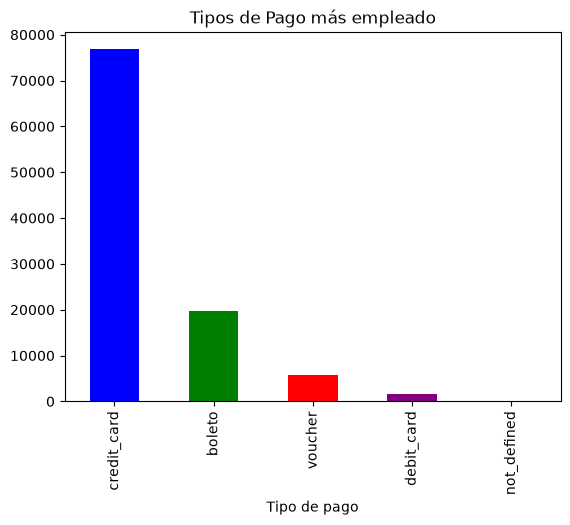

Text(0.5, 1.0, 'Metodos de pago')

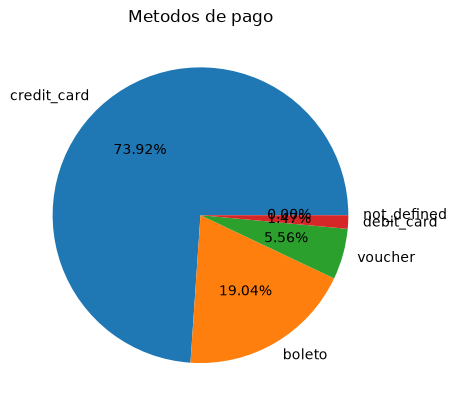

In [11]:
pagos = payments["payment_type"].value_counts()
ax = pagos.plot(
    kind="bar",
    color=["Blue","Green","Red","Purple", "Gray" ]
)
ax.set_title("Tipos de Pago más empleado")
ax.set_xlabel("Tipo de pago")
ax.set_ylabel("")
plt.show()

ax2 = pagos.plot(
    kind="pie",
    autopct = "%1.2f%%"
)
ax2.set_title("Metodos de pago")

#### ¿Cuál utilizarías en un reporte para comparar los métodos de pago?
El grafico de barras, es más claro y conciso.
#### ¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?
El grafico de tipo "pie", se representa de manera particionada cada uno de los elementos.
